# LIA — Análise 3: alfabetismo funcional
**Base utilizada: INAF 2024 — tabelas do relatório**

**Grupo: AuxiLia**

**Integrantes:**
- Vinicius Kozonoe Guaglini — RM 567264
- João Victor Melo Santos — RM 566640
- Yan Lucas Gonçalves da Silva — RM 567046
- Murilo Jeronimo Ferreira Nunes — RM 560641


Saber ler algumas palavras não significa necessariamente compreender instruções, formulários e mensagens mais complexas. Esse é um dos motivos para considerarmos o alfabetismo funcional no desenvolvimento da LIA.

Aqui vamos observar o **analfabetismo funcional ao longo das edições do INAF** e comparar os percentuais de 2024 por idade, escolaridade, sexo e renda. Também vamos olhar a tabela de desempenho digital, que ajuda a relacionar o tema da leitura com as atividades realizadas em ambientes digitais.

**Perguntas que queremos responder:**
1. Como o analfabetismo funcional mudou entre as edições do INAF?
2. Como ele varia com a idade, a escolaridade e a renda?
3. O que os indicadores sugerem para tornar as tarefas digitais mais acessíveis?

**Importante:** os seis CSVs foram organizados a partir de tabelas consolidadas do relatório. Não temos as respostas individuais dos participantes. Portanto, as comparações serão descritivas e não permitem cruzar características de uma mesma pessoa.


## 1. Localizando os dados

Os seis arquivos CSV desta etapa estão em `datasets/raw/inaf`. O código abaixo procura essa pasta dentro da entrega.

Se a professora abrir no Jupyter, os arquivos serão lidos diretamente da pasta extraída. Se abrir no Google Colab e os arquivos ainda não estiverem lá, deverá enviar o **ZIP completo da entrega** quando a primeira célula pedir.


In [1]:
from pathlib import Path
from IPython.display import display
import zipfile

# Os arquivos ficam ao lado dos notebooks, dentro da pasta datasets.
SUBPASTA = "inaf"
caminhos = [Path.cwd(), Path.cwd() / "GS_LIA_DataScience",
            Path("/content/GS_LIA_DataScience")]
RAIZ = next((p for p in caminhos if (p / "datasets/raw" / SUBPASTA).is_dir()), None)

if RAIZ is None:
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(
            "Pasta de dados não encontrada. Extraia o ZIP completo e abra o notebook "
            "a partir da pasta GS_LIA_DataScience."
        )

    print("Selecione o arquivo GS_LIA_DataScience.zip (ZIP completo da entrega).")
    enviados = files.upload()
    nome_zip = next((nome for nome in enviados if nome.lower().endswith(".zip")), None)
    if nome_zip is None:
        raise FileNotFoundError("Você precisa enviar o ZIP completo, não um CSV isolado.")

    with zipfile.ZipFile(nome_zip) as pacote:
        destino = Path("/content").resolve()
        if any(not (destino / item.filename).resolve().is_relative_to(destino)
               for item in pacote.infolist()):
            raise ValueError("O ZIP contém um caminho inválido.")
        pacote.extractall(destino)

    RAIZ = Path("/content/GS_LIA_DataScience")

PASTA = RAIZ / "datasets" / "raw" / SUBPASTA
if not PASTA.is_dir():
    raise FileNotFoundError(f"Não encontrei a pasta: {PASTA}")

print("Pasta de dados:", PASTA)
import pandas as pd
import matplotlib.pyplot as plt

pasta = PASTA
print("CSVs disponíveis:", len(list(pasta.glob("*.csv"))))


Pasta de dados: /mnt/data/_lia_revision/GS_LIA_DataScience/datasets/raw/inaf


CSVs disponíveis: 6


## 2. Lendo as tabelas

Cada arquivo tem um assunto diferente. Vamos colocar as tabelas em um dicionário para acessá-las pelo nome (`idade`, `escolaridade`, `renda` etc.) sem misturar os dados.


In [2]:
arquivos = {
    'historico': 'inaf_serie_historica.csv',
    'escolaridade': 'inaf_escolaridade_2024.csv',
    'idade': 'inaf_faixa_etaria_2024.csv',
    'sexo': 'inaf_sexo_2024.csv',
    'renda': 'inaf_renda_2024.csv',
    'digital': 'inaf_desempenho_digital_2024.csv'
}

dados = {}
for nome, arquivo in arquivos.items():
    dados[nome] = pd.read_csv(pasta / arquivo, encoding='utf-8-sig')
    print(nome, dados[nome].shape)

historico (60, 4)
escolaridade (25, 7)
idade (20, 7)
sexo (10, 7)
renda (20, 7)
digital (3, 4)


## 3. Primeira conferência

Antes dos cálculos, mostramos algumas linhas, os tipos de coluna e a quantidade de valores vazios ou duplicados. Como os dados já estão resumidos por categoria, uma linha representa um percentual publicado e não uma pessoa entrevistada.


In [3]:
for nome, df in dados.items():
    print('\n', nome.upper())
    display(df.head())
    print('Tipos:')
    print(df.dtypes)
    print('Vazios:', df.isna().sum().sum(), '| Duplicadas:', df.duplicated().sum())


 HISTORICO


,edicao,indicador,percentual,tabela
0,2001-2002,Analfabeto,12,Tabela 3
1,2001-2002,Rudimentar,27,Tabela 3
2,2001-2002,Elementar,28,Tabela 3
3,2001-2002,Intermediário,20,Tabela 3
4,2001-2002,Proficiente,12,Tabela 3


Tipos:
edicao        object
indicador     object
percentual     int64
tabela        object
dtype: object
Vazios: 0 | Duplicadas: 0

 ESCOLARIDADE


,ano,grupo,categoria,nivel_alfabetismo,percentual_no_grupo,base_ponderada_publicada,tabela
0,2024,Escolaridade,Nenhuma,Analfabeto,88,67,4a
1,2024,Escolaridade,Nenhuma,Rudimentar,10,67,4a
2,2024,Escolaridade,Nenhuma,Elementar,0,67,4a
3,2024,Escolaridade,Nenhuma,Intermediário,2,67,4a
4,2024,Escolaridade,Nenhuma,Proficiente,0,67,4a


Tipos:
ano                          int64
grupo                       object
categoria                   object
nivel_alfabetismo           object
percentual_no_grupo          int64
base_ponderada_publicada     int64
tabela                      object
dtype: object
Vazios: 0 | Duplicadas: 0

 IDADE


,ano,grupo,categoria,nivel_alfabetismo,percentual_no_grupo,base_ponderada_publicada,tabela
0,2024,Faixa etária,15 a 29,Analfabeto,2,810,5a
1,2024,Faixa etária,15 a 29,Rudimentar,14,810,5a
2,2024,Faixa etária,15 a 29,Elementar,39,810,5a
3,2024,Faixa etária,15 a 29,Intermediário,32,810,5a
4,2024,Faixa etária,15 a 29,Proficiente,13,810,5a


... (3 outputs left out)

,ano,grupo,categoria,nivel_alfabetismo,percentual_no_grupo,base_ponderada_publicada,tabela
0,2024,Renda familiar,Até 1 salário mínimo,Analfabeto,14,791,9a
1,2024,Renda familiar,Até 1 salário mínimo,Rudimentar,31,791,9a
2,2024,Renda familiar,Até 1 salário mínimo,Elementar,39,791,9a
3,2024,Renda familiar,Até 1 salário mínimo,Intermediário,14,791,9a
4,2024,Renda familiar,Até 1 salário mínimo,Proficiente,2,791,9a


Tipos:
ano                          int64
grupo                       object
categoria                   object
nivel_alfabetismo           object
percentual_no_grupo          int64
base_ponderada_publicada     int64
tabela                      object
dtype: object
Vazios: 0 | Duplicadas: 0

 DIGITAL


,ano,desempenho_digital,percentual,grafico
0,2024,Baixo,25,Gráfico 20
1,2024,Médio,53,Gráfico 20
2,2024,Alto,23,Gráfico 20


Tipos:
ano                    int64
desempenho_digital    object
percentual             int64
grafico               object
dtype: object
Vazios: 0 | Duplicadas: 0


## 4. Como o analfabetismo funcional mudou?

Primeiro usamos a tabela histórica. Selecionamos o indicador de analfabetismo funcional e montamos um gráfico com os percentuais publicados em cada edição.

Na sequência, mostramos os indicadores disponíveis para 2024. O gráfico permite observar o histórico, mas não devemos assumir que cada diferença entre edições tenha uma causa específica sem uma análise metodológica adicional.


,edicao,percentual
5,2001-2002,39
11,2002-2003,39
17,2003-2004,37
23,2004-2005,37
29,2007,34
35,2009,27
41,2011,27
47,2015,27
53,2018,29
59,2024,29


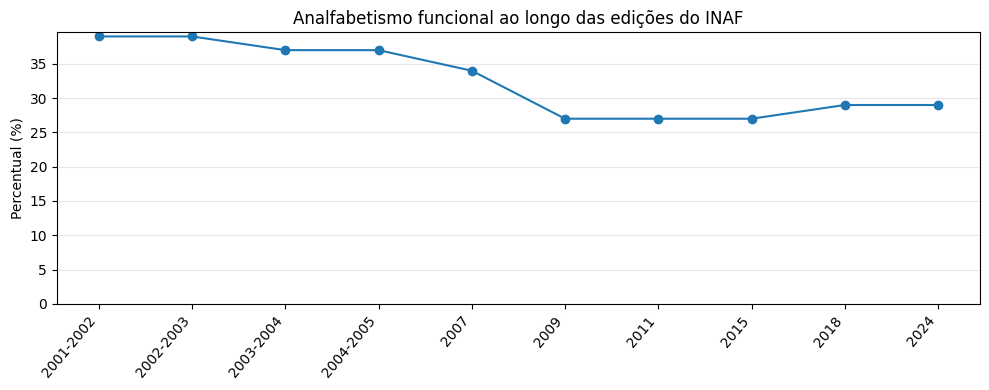

In [4]:
historico = dados['historico']
funcional = historico[historico['indicador'] == 'Analfabetismo funcional (publicado)'].copy()
display(funcional[['edicao', 'percentual']])

plt.figure(figsize=(10, 4))
plt.plot(funcional['edicao'], funcional['percentual'], marker='o')
plt.xticks(rotation=50, ha='right')
plt.ylabel('Percentual (%)')
plt.ylim(bottom=0)
plt.title('Analfabetismo funcional ao longo das edições do INAF')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
saida_grafico = RAIZ / 'outputs' / 'inaf'
saida_grafico.mkdir(parents=True, exist_ok=True)
plt.savefig(saida_grafico / 'historico_analfabetismo_funcional.png', dpi=160)
plt.show()

In [5]:
atual = historico[historico['edicao'].astype(str).str.contains('2024')]
print('Indicadores disponíveis para 2024:')
display(atual[['indicador', 'percentual']])

Indicadores disponíveis para 2024:


,indicador,percentual
54,Analfabeto,7
55,Rudimentar,22
56,Elementar,36
57,Intermediário,25
58,Proficiente,10
59,Analfabetismo funcional (publicado),29


## 5. Comparando os grupos em 2024

No INAF, o analfabetismo funcional reúne as categorias **Analfabeto** e **Rudimentar**. Para cada faixa etária, escolaridade, sexo e renda, somamos os percentuais desses dois níveis.

Os gráficos mostram as diferenças encontradas. Como os percentuais do relatório foram arredondados, algumas somas podem variar um pouco em relação aos totais oficiais.



 IDADE


,analfabetismo_funcional_%
categoria,
15 a 29,16
30 a 39,23
40 a 49,33
50 a 64,51


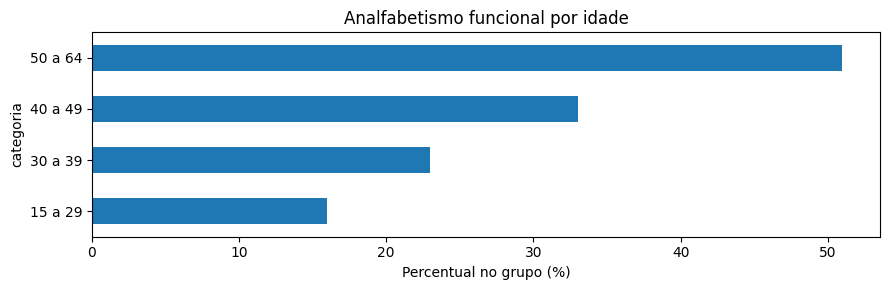


 ESCOLARIDADE


,analfabetismo_funcional_%
categoria,
Nenhuma,98
Fundamental - anos iniciais,78
Fundamental - anos finais,43
Ensino médio,17
Superior completo ou mais,12


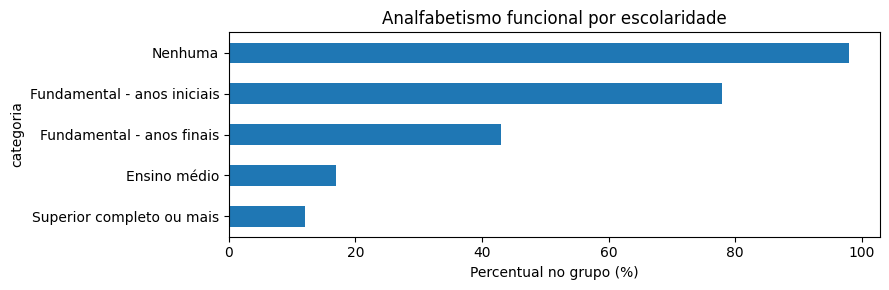


 SEXO


,analfabetismo_funcional_%
categoria,
Homens,32
Mulheres,27


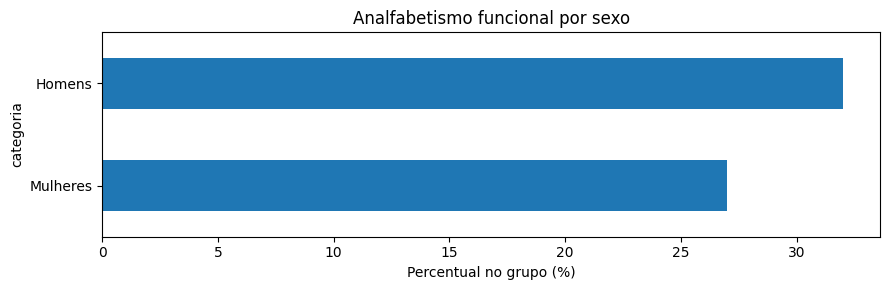


 RENDA


,analfabetismo_funcional_%
categoria,
Até 1 salário mínimo,45
Mais de 1 a 2 salários mínimos,29
Mais de 2 a 5 salários mínimos,15
Mais de 5 salários mínimos,11


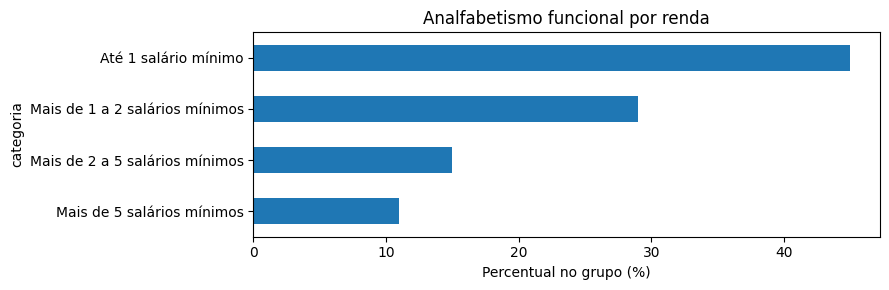

In [6]:
for nome in ['idade', 'escolaridade', 'sexo', 'renda']:
    df = dados[nome]
    resumo = df[df['nivel_alfabetismo'].isin(['Analfabeto', 'Rudimentar'])]
    resumo = resumo.groupby('categoria', sort=False)['percentual_no_grupo'].sum()
    print('\n', nome.upper())
    display(resumo.to_frame('analfabetismo_funcional_%'))

    plt.figure(figsize=(9, max(3, len(resumo) * 0.5)))
    resumo.sort_values().plot(kind='barh')
    plt.xlabel('Percentual no grupo (%)')
    plt.title('Analfabetismo funcional por ' + nome)
    plt.tight_layout()
    plt.show()

## 6. Distribuição dos níveis por idade

Além de olhar apenas o analfabetismo funcional, vamos comparar os cinco níveis de alfabetismo dentro de cada faixa etária. O gráfico de barras empilhadas permite ver como eles se distribuem.

Isso ajuda a perceber que não existem só dois extremos (“sabe ler” e “não sabe ler”): a compreensão de textos e informações pode ocorrer em diferentes níveis.


nivel_alfabetismo,Analfabeto,Rudimentar,Elementar,Intermediário,Proficiente
categoria,,,,,
15 a 29,2,14,39,32,13
30 a 39,3,20,40,26,12
40 a 49,9,24,35,24,7
50 a 64,16,35,28,13,7


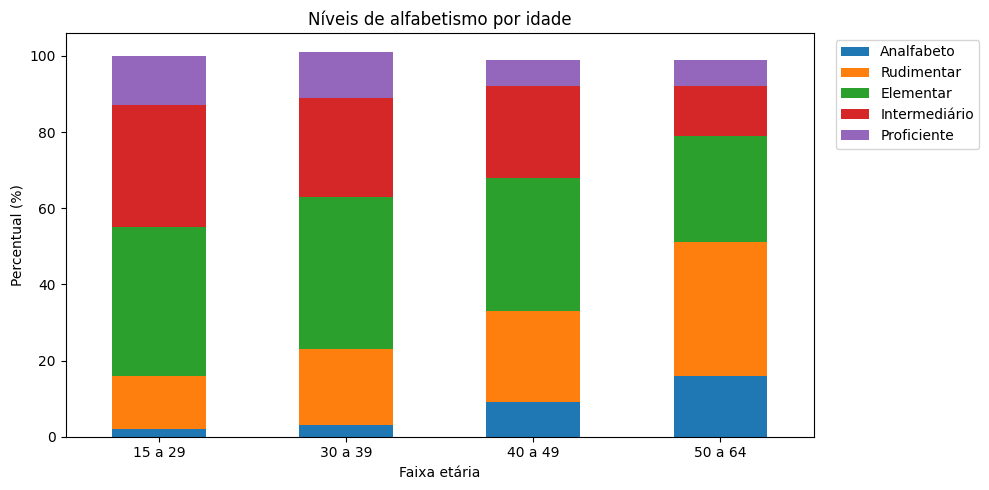

In [7]:
idade = dados['idade']
tabela_idade = idade.pivot(index='categoria', columns='nivel_alfabetismo', values='percentual_no_grupo')
ordem = ['Analfabeto', 'Rudimentar', 'Elementar', 'Intermediário', 'Proficiente']
tabela_idade = tabela_idade.reindex(columns=ordem)
display(tabela_idade)
tabela_idade.plot(kind='bar', stacked=True, figsize=(10, 5))
plt.ylabel('Percentual (%)')
plt.xlabel('Faixa etária')
plt.title('Níveis de alfabetismo por idade')
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 7. Desempenho em tarefas digitais

Aqui usamos a tabela específica de desempenho digital do relatório. Mostramos os percentuais e criamos um gráfico simples para comparar as categorias publicadas.

Essa tabela complementa a discussão sobre acessibilidade digital, mas não permite identificar quais pessoas das análises anteriores tiveram determinado desempenho.


,ano,desempenho_digital,percentual,grafico
0,2024,Baixo,25,Gráfico 20
1,2024,Médio,53,Gráfico 20
2,2024,Alto,23,Gráfico 20


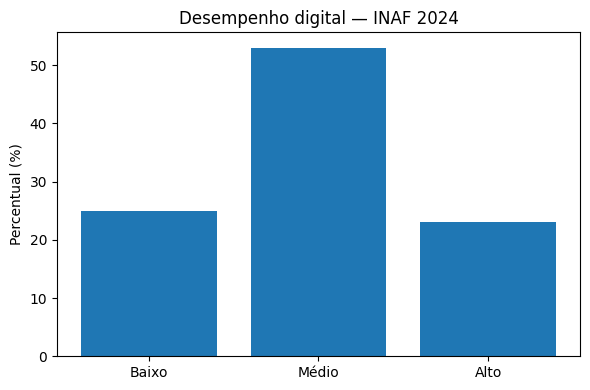

In [8]:
digital = dados['digital']
display(digital)
plt.figure(figsize=(6, 4))
plt.bar(digital['desempenho_digital'], digital['percentual'])
plt.ylabel('Percentual (%)')
plt.title('Desempenho digital — INAF 2024')
plt.tight_layout()
plt.show()

## 8. Conferindo os percentuais

Nesta etapa calculamos estatísticas descritivas dos percentuais de cada arquivo e conferimos se os níveis de alfabetismo de cada grupo somam aproximadamente 100%.

Esses valores são **resumos de percentuais de tabelas**, não médias individuais de alfabetismo. Essa diferença é importante para não tirar conclusões que os dados não permitem.


In [9]:
for nome, df in dados.items():
    coluna = 'percentual_no_grupo' if 'percentual_no_grupo' in df.columns else 'percentual'
    print('\n', nome.upper())
    display(df[coluna].describe().round(2))

for nome in ['idade', 'escolaridade', 'sexo', 'renda']:
    somas = dados[nome].groupby('categoria')['percentual_no_grupo'].sum()
    print(nome, '- soma por categoria (aprox. 100%):')
    print(somas.to_string())


 HISTORICO


count    60.00
mean     22.13
std      10.01
min       4.00
25%      12.00
50%      23.00
75%      29.00
max      42.00
Name: percentual, dtype: float64


 ESCOLARIDADE


count    25.00
mean     20.04
std      21.20
min       0.00
25%       2.00
50%      14.00
75%      29.00
max      88.00
Name: percentual_no_grupo, dtype: float64


 IDADE


count    20.00
mean     19.95
std      12.08
min       2.00
25%      11.25
50%      18.00
75%      29.00
max      40.00
Name: percentual_no_grupo, dtype: float64

... (3 outputs left out)

count    20.00
mean     19.95
std      13.36
min       1.00
25%       9.00
50%      18.50
75%      31.75
max      39.00
Name: percentual_no_grupo, dtype: float64


 DIGITAL


count     3.00
mean     33.67
std      16.77
min      23.00
25%      24.00
50%      25.00
75%      39.00
max      53.00
Name: percentual, dtype: float64

idade - soma por categoria (aprox. 100%):
categoria
15 a 29    100
30 a 39    101
40 a 49     99
50 a 64     99
escolaridade - soma por categoria (aprox. 100%):
categoria
Ensino médio                   100
Fundamental - anos finais      100
Fundamental - anos iniciais    100
Nenhuma                        100
Superior completo ou mais      101
sexo - soma por categoria (aprox. 100%):
categoria
Homens      101
Mulheres     99
renda - soma por categoria (aprox. 100%):
categoria
Até 1 salário mínimo              100
Mais de 1 a 2 salários mínimos    100
Mais de 2 a 5 salários mínimos     99
Mais de 5 salários mínimos        100


## 9. Salvando tabelas para o relatório

Para não precisar copiar resultados manualmente, salvamos um CSV com o percentual de analfabetismo funcional de cada grupo de idade, escolaridade, sexo e renda. Os arquivos são criados na pasta `outputs/inaf`.


In [10]:
saida = RAIZ / 'outputs' / 'inaf'
saida.mkdir(parents=True, exist_ok=True)

for nome in ['idade', 'escolaridade', 'sexo', 'renda']:
    df = dados[nome]
    tabela = df[df['nivel_alfabetismo'].isin(['Analfabeto', 'Rudimentar'])]
    tabela = tabela.groupby('categoria', sort=False, as_index=False)['percentual_no_grupo'].sum()
    tabela = tabela.rename(columns={'percentual_no_grupo': 'analfabetismo_funcional_pct'})
    tabela.to_csv(saida / f'resumo_{nome}.csv', index=False)

print('Tabelas salvas em:', saida)

Tabelas salvas em: /mnt/data/_lia_revision/GS_LIA_DataScience/outputs/inaf


## 10. Principais resultados e relação com a AuxiLia

Segundo o INAF 2024, **29% das pessoas de 15 a 64 anos no Brasil são analfabetas funcionais**, o que significa enfrentar dificuldades para compreender e utilizar textos, números ou informações em situações cotidianas. A proporção chega a **51% entre os adultos de 50 a 64 anos**, evidenciando uma diferença importante por idade. As comparações por escolaridade e renda também mostram que o problema não está distribuído igualmente entre os grupos sociais.

Esses dados motivam o projeto **AuxiLia** a priorizar comandos de voz, leitura de orientações e explicações simples em etapas. O INAF **não inclui pessoas com 65 anos ou mais**; para essa faixa, o notebook do Censo ajuda a contextualizar a alfabetização, embora não meça o mesmo conceito. Os CSVs do INAF são **tabelas consolidadas do relatório**, não microdados individuais. Por isso, não podemos afirmar que os mesmos indivíduos têm dificuldade de leitura e dificuldade digital ou que a solução já foi validada.

**Fonte:** INAF Brasil 2024, relatório *Alfabetismo: do analógico ao digital* — https://acaoeducativa.org.br/publicacoes/relatorio-inaf-brasil-2024-alfabetismo-do-analogico-ao-digital/
